# Retornos do zero

**Por que uma queda dói mais do que a mesma alta ajuda: retorno simples e retorno log, a composição, a escala log, por que a soma dos % erra (e para que lado), o preço lognormal, a carteira, o Ibovespa ano a ano desde 1995, a replicação de Hudson & Gregoriou (2015) em 38 ações da B3, a posição alavancada e o CDI de cada dia**

Gabriel Pires · [@gabrielp.piress](https://instagram.com/gabrielp.piress) · [gabrielppires.com](https://gabrielppires.com) · série *Finanças Quantitativas do Zero* · outubro de 2026

---

Perca 50 % e você precisa de **100 %** só para empatar. O vídeo mostra por quê em 13 linhas de Python: variações em porcentagem **multiplicam**, e retornos log **somam**. Este notebook reproduz cada número dele e vai além:

| Seção | O que você leva |
|---|---|
| 0 | O código da tela (`retornos.py`), linha por linha, e um `assert` para cada número do vídeo |
| 1 | Um retorno é medido de onde você começa: eqs. (1) e (2), e a tabela de recuperação, eq. (3) |
| 2 | O retorno log, eq. (4), e a escala log: cada metade é o mesmo passo |
| 3 | Somar no tempo, eq. (5): o ano simulado, −24 % no papel e −25 % de verdade |
| 4 | Por que a soma dos % erra, e para que lado: Taylor, eq. (6) |
| 5 | Dias pequenos, dias grandes: +1 % é 0,00995, e −100 % é −∞ |
| 6 | Por que os quants amam o log: preço sempre positivo e o preço lognormal, eq. (7) |
| 7 | Entre ativos, quem soma é o retorno simples: a carteira, eq. (8) |
| 8 | Dado real: o Ibovespa ano a ano desde 1995 |
| 9 | Replicação: Hudson & Gregoriou (2015) em 38 ações da B3, eq. (9) |
| 10 | Mesa de operações: P&L de um long-short em R\$ e a posição alavancada |
| 11 | Investidor: a "média de 1 % ao mês", o CDI de cada dia e o tempo para voltar ao topo |
| 12 | O que este modelo não vê + exercícios |

**Dados:** as seções 0 a 7 usam os números do vídeo (preços em dólar, como no original, e a ação simulada com semente 5). As seções 8 a 11 usam dados reais e públicos, em `dados/`: o Ibovespa diário (fechamento do `^BVSP` no Yahoo Finance, de 29/12/1994 a 16/10/2026; o Ibovespa é um índice de retorno total), o CDI diário (série 12 do SGS do Banco Central, de 02/01/1995 a 16/10/2026) e 38 ações da B3 ajustadas por proventos (Yahoo Finance, de 02/01/2015 a 09/10/2026).

> O vídeo é inspirado em *Quant Finance from Scratch*, de [@quantfinancetogo](https://instagram.com/quantfinancetogo). Só educação. Não é recomendação de investimento.

## 0. O código da tela

São as 13 linhas que aparecem digitadas no vídeo. Tudo o que vem depois explica, verifica e estende estas linhas.

In [1]:
import numpy as np
p = np.array([100, 50, 100])   # queda, depois recuperação
pct = p[1:] / p[:-1] - 1          # -50 %, +100 %
print(pct, pct.sum())             # soma: +50 % ?!
log = np.log(p[1:] / p[:-1])    # -0.69, +0.69
print(log, log.sum())             # soma: 0, exato
rng = np.random.default_rng(5)  # ação simulada
pct = rng.normal(0, 0.02, 252)  # um ano de dias
preco = 100 * np.cumprod(1 + pct)
print(preco[-1] / 100 - 1)        # retorno real do ano
print(pct.sum())                  # soma dos %: errada
log = np.log(1 + pct)             # os mesmos dias, em log
print(np.exp(log.sum()) - 1)     # somando logs: exato

[-0.5  1. ] 0.5
[-0.69314718  0.69314718] 0.0
-0.2501051148297655
-0.23957590108940638
-0.2501051148297653


### Os números do vídeo

Um `assert` para cada número que aparece na tela ou é falado, com a tolerância do arredondamento falado. As linhas 3 e 5 do código reaproveitam os nomes `pct` e `log`; aqui os três preços ganham nomes próprios.

In [2]:
pct3, log3 = p[1:] / p[:-1] - 1, np.log(p[1:] / p[:-1])
assert pct3.tolist() == [-0.5, 1.0] and pct3.sum() == 0.5                  # −50 % e +100 %: "+50 % no papel"
assert p[-1] == p[0] == 100                                                # "você está de volta exatamente nos 100 dólares"
assert 100 * 0.5 == 50 and 50 * 0.5 == 25 and 100 - (50 + 25) == 25        # −50 % tira $50; +50 % de $50 devolve só $25; ainda faltam $25
assert 50 * 1.5 == 75 and 100 * 0.5 * 2 == 100                            # × 1,5 dá $75; × ½ e depois × 2 volta aos $100
assert 1 / (1 - 0.5) - 1 == 1.0                                            # perde 50 %, precisa de 100 %
assert [round(float(v), 2) for v in log3] == [-0.69, 0.69] and log3.sum() == 0   # ln(50/100) = −0,69; ln(100/50) = +0,69; juntos: exatamente 0
escada = np.array([25, 50, 100, 200, 400])                                 # o eixo da escala log no vídeo
assert np.allclose(np.diff(np.log(escada)), np.log(2)) and round(float(np.log(2)), 2) == 0.69   # cada metade/dobro: passo de 0,69

real, soma_pct, soma_log = preco[-1] / 100 - 1, pct.sum(), np.exp(log.sum()) - 1
assert len(pct) == 252 and round(float(pct.std()), 2) == 0.02              # 252 dias, "cerca de 2 por cento ao dia"
assert round(100 * real, 1) == -25.0 and round(100 * soma_pct, 1) == -24.0 # "ela realmente perdeu 25"; a soma dos % dá −24
assert abs(soma_log - real) < 1e-12                                        # somando logs: exatamente os −25 % reais
cum_pct, cum_real = np.cumsum(pct), preco / 100 - 1                        # os números que correm no painel do ano
assert [round(100 * cum_pct[28], 1), round(100 * cum_real[28], 1)] == [-12.7, -12.3]       # "dia 29 de 252"
assert [round(100 * cum_pct[181], 1), round(100 * cum_real[181], 1)] == [-35.2, -31.9]     # "dia 182 de 252"
assert round(float(np.log(1.01)), 5) == 0.00995 and round(float(np.log(1.01)), 2) == 0.01  # "+1 % é cerca de 0,01": 0,0100 vs 0,00995

print("$100 → $50 → $100:   simples", pct3, " soma", pct3.sum(), "  |  log", log3.round(4), " soma", log3.sum())
print(f"ano simulado: real {100 * real:.1f} %  |  soma dos % {100 * soma_pct:.1f} %  |  exp(Σ log) − 1 = {100 * soma_log:.1f} %".replace(".", ","))
print(f"ln(1,01) = {np.log(1.01):.5f}  |  ln 2 = {np.log(2):.4f}".replace(".", ","))

$100 → $50 → $100:   simples [-0.5  1. ]  soma 0.5   |  log [-0.6931  0.6931]  soma 0.0
ano simulado: real -25,0 %  |  soma dos % -24,0 %  |  exp(Σ log) − 1 = -25,0 %
ln(1,01) = 0,00995  |  ln 2 = 0,6931


### Bibliotecas e estilo dos gráficos

In [3]:
import math
import pandas as pd
import matplotlib.pyplot as plt

NAVY, BLUE, LIGHT, AMBER, GOLD, RED, GREEN, GREY = "#1B2A4A", "#1E56B8", "#5B8DEF", "#F2B544", "#B7791F", "#B42318", "#1B7A4A", "#6B7590"
plt.rcParams.update({
    "figure.figsize": (9, 4.6), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": GREY, "axes.labelcolor": NAVY,
    "xtick.color": GREY, "ytick.color": GREY, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "text.parse_math": False,          # "R$ 1 ... R$ 2" é dinheiro, não fórmula
})
br = lambda v, d=2: f"{v:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".").replace("-", "−")   # 1.234,56
pc = lambda v, d=1: br(100 * v, d) + " %"                                    # fração -> "−25,0 %"
pcs = lambda v, d=1: ("+" if v > 0 else "") + pc(v, d)                       # com sinal
usd = lambda v, d=2: "$" + br(v, d)
brl = lambda v, d=2: ("−" if v < 0 else "") + "R$ " + br(abs(v), d)
def mostra(df, legenda=None):
    s = df.style.hide(axis="index")
    display(s.set_caption(legenda) if legenda else s)

## 1. Um retorno é medido de onde você começa — eqs. (1), (2) e (3)

O **retorno simples** de um período é a variação do preço dividida pelo preço de **partida**:

$$
R_t = \frac{P_t}{P_{t-1}} - 1 \tag{1}
$$

De \$100, cair 50 % tira \$50. De \$50, subir 50 % devolve só \$25: a base encolheu. Em vários períodos, quem se acumula é o fator $1 + R$, e os fatores **multiplicam**:

$$
1 + R_{0 \to T} = \prod_{t=1}^{T} (1 + R_t) \tag{2}
$$

Cair 50 % é multiplicar por ½; só multiplicar por 2 desfaz isso, e × 2 é +100 %. Em geral, a alta que desfaz uma queda $R$ sai de $(1+R)(1+R^\ast) = 1$:

$$
R^\ast = \frac{1}{1+R} - 1 = \frac{-R}{1+R} \tag{3}
$$

retornos simples (1): −50 % e +100 %  →  composição (2): 0,5 × 2 = 1,0, retorno total 0 %
somar no papel: −50 % +100 % = +50 %, mas o preço voltou a $100
depois da queda, +50 % de $50 = $75: ainda faltam $25
cair 20 % e subir 20 %: 0,8 × 1,2 − 1 = −4,0 %


queda,"alta que desfaz, eq. (3)",o preço precisa ser multiplicado por
−5 %,"+5,3 %","1,05"
−10 %,"+11,1 %","1,11"
−20 %,"+25,0 %","1,25"
−25 %,"+33,3 %","1,33"
−30 %,"+42,9 %","1,43"
−50 %,"+100,0 %","2,00"
−65 %,"+185,7 %","2,86"
−80 %,"+400,0 %","5,00"
−90 %,"+900,0 %","10,00"
−99 %,"+9.900,0 %","100,00"


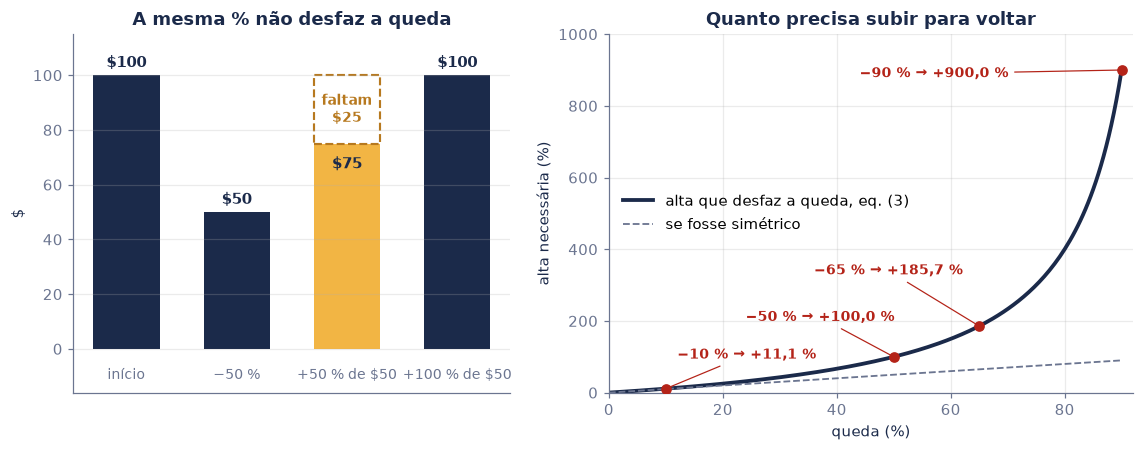

In [4]:
P = np.array([100.0, 50.0, 100.0])
R = P[1:] / P[:-1] - 1                                          # (1)
print(f"retornos simples (1): {pcs(R[0], 0)} e {pcs(R[1], 0)}  →  composição (2): 0,5 × 2 = {br(np.prod(1 + R), 1)}, retorno total {pc(np.prod(1 + R) - 1, 0)}")
print(f"somar no papel: {pcs(R[0], 0)} {pcs(R[1], 0)} = {pcs(R.sum(), 0)}, mas o preço voltou a {usd(P[-1], 0)}")
print(f"depois da queda, +50 % de $50 = {usd(50 * 1.5, 0)}: ainda faltam {usd(100 - 50 * 1.5, 0)}")
print(f"cair 20 % e subir 20 %: 0,8 × 1,2 − 1 = {pcs(0.8 * 1.2 - 1, 1)}")

quedas = np.array([-0.05, -0.10, -0.20, -0.25, -0.30, -0.50, -0.65, -0.80, -0.90, -0.99])
volta = 1 / (1 + quedas) - 1                                    # (3)
mostra(pd.DataFrame({"queda": [pc(q, 0) for q in quedas], "alta que desfaz, eq. (3)": [pcs(v, 1) for v in volta],
                     "o preço precisa ser multiplicado por": [br(1 / (1 + q), 2) for q in quedas]}))
assert [round(100 * v, 1) for v in volta[[1, 5, 8]]] == [11.1, 100.0, 900.0]
assert round(0.8 * 1.2 - 1, 2) == -0.04

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
xs, hs = [0, 1, 2, 3], [100, 50, 75, 100]
a1.bar(xs, hs, color=[NAVY, NAVY, AMBER, NAVY], width=0.6)
a1.bar(2, 25, bottom=75, color="none", edgecolor=GOLD, ls="--", lw=1.4, width=0.6)
a1.text(2, 87.5, "faltam\n$25", ha="center", va="center", color=GOLD, weight="bold", fontsize=9)
for x, h, s in zip(xs, hs, ["início", "−50 %", "+50 % de $50", "+100 % de $50"]):
    a1.text(x, h + 3 if x != 2 else h - 9, usd(h, 0), ha="center", color=NAVY, weight="bold")
    a1.text(x, -11, s, ha="center", color=GREY, fontsize=9)
a1.set(title="A mesma % não desfaz a queda", ylim=(-16, 115), xticks=[], ylabel="$")
q = np.linspace(0, 0.9, 200)
a2.plot(100 * q, 100 * (1 / (1 - q) - 1), color=NAVY, lw=2.5, label="alta que desfaz a queda, eq. (3)")
a2.plot(100 * q, 100 * q, color=GREY, ls="--", lw=1.2, label="se fosse simétrico")
for x, xy_txt in ((0.10, (12, 95)), (0.50, (24, 200)), (0.65, (36, 330)), (0.90, (44, 880))):
    y = 1 / (1 - x) - 1
    a2.scatter([100 * x], [100 * y], color=RED, zorder=3, s=36)
    a2.annotate(f"−{br(100 * x, 0)} % → +{br(100 * y, 1)} %", (100 * x, 100 * y), xy_txt, color=RED, weight="bold", fontsize=9,
                arrowprops=dict(arrowstyle="-", color=RED, lw=0.8))
a2.set(title="Quanto precisa subir para voltar", xlabel="queda (%)", ylabel="alta necessária (%)", ylim=(0, 1000), xlim=(0, 92))
a2.legend(frameon=False, loc="center left"); plt.tight_layout(); plt.show()

**Leitura.** A tabela é assimétrica porque a eq. (3) tem $1+R$ no denominador: quedas pequenas pedem altas quase iguais (−5 % pede +5,3 %), quedas grandes pedem altas enormes (−90 % pede +900 %). É a frase de abertura do vídeo: perca 50 % e você precisa de 100 % só para empatar. Na seção 11, a mesma tabela aparece nas maiores quedas do Ibovespa.

## 2. O retorno log — eq. (4)

Os quants medem o retorno pelo **logaritmo natural** da razão de preços:

$$
r_t = \ln\frac{P_t}{P_{t-1}} = \ln(1 + R_t) \tag{4}
$$

A queda de \$100 para \$50 vira $\ln(1/2) = -0{,}6931$; a alta de volta vira $\ln 2 = +0{,}6931$. Juntas, **exatamente zero**. Pela eq. (3), a alta que desfaz $R$ tem $1 + R^\ast = 1/(1+R)$, e o log de um inverso é o oposto: $\ln(1+R^\ast) = -\ln(1+R)$. **No log, a queda e a alta que a desfaz têm o mesmo tamanho.**

Na escala log, cada metade é o mesmo passo para baixo e cada dobro o mesmo passo para cima: de \$400 a \$25, quatro passos de 0,69.

queda,alta que desfaz,queda em log (4),alta em log (4)
−10 %,"+11,1 %","−0,1054","+0,1054"
−25 %,"+33,3 %","−0,2877","+0,2877"
−50 %,"+100,0 %","−0,6931","+0,6931"
−75 %,"+300,0 %","−1,3863","+1,3863"
−90 %,"+900,0 %","−2,3026","+2,3026"


escada $25 → $400, passos em log: 0,6931 · 0,6931 · 0,6931 · 0,6931   (ln 2 = 0,6931)


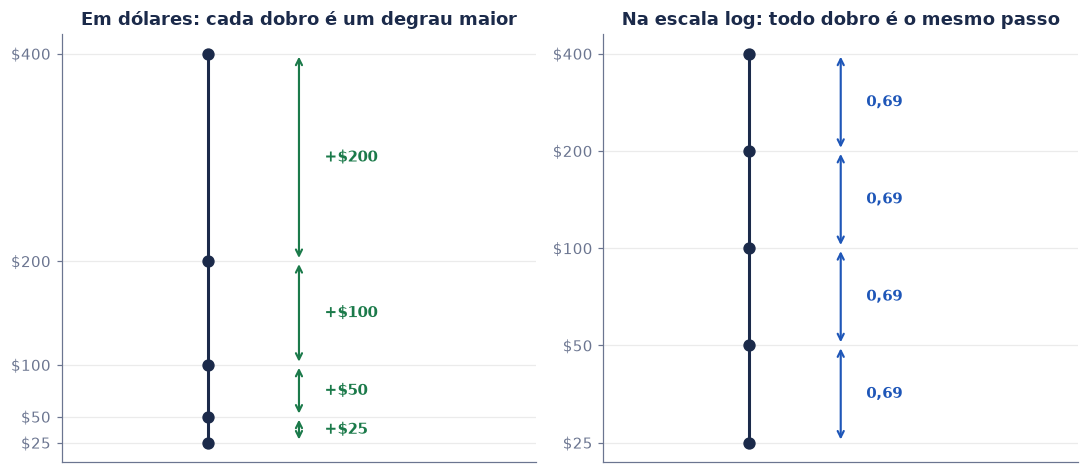

In [5]:
pares = np.array([-0.10, -0.25, -0.50, -0.75, -0.90])
desfaz = 1 / (1 + pares) - 1
mostra(pd.DataFrame({"queda": [pc(x, 0) for x in pares], "alta que desfaz": [pcs(x, 1) for x in desfaz],
                     "queda em log (4)": [br(x, 4) for x in np.log1p(pares)], "alta em log (4)": [("+" + br(x, 4)) for x in np.log1p(desfaz)]}))
assert np.allclose(np.log1p(pares), -np.log1p(desfaz))
passos = np.diff(np.log(escada))
print("escada $25 → $400, passos em log:", " · ".join(br(x, 4) for x in passos), f"  (ln 2 = {br(np.log(2), 4)})")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, titulo in ((a1, "Em dólares: cada dobro é um degrau maior"), (a2, "Na escala log: todo dobro é o mesmo passo")):
    ax.scatter([0] * 5, escada, color=NAVY, s=50, zorder=3)
    ax.plot([0, 0], [25, 400], color=NAVY, lw=2)
    for lo, hi in zip(escada[:-1], escada[1:]):
        ax.annotate("", xy=(0.25, hi), xytext=(0.25, lo), arrowprops=dict(arrowstyle="<->", color=GREEN if ax is a1 else BLUE, lw=1.4))
        ax.text(0.32, math.sqrt(lo * hi) if ax is a2 else (lo + hi) / 2, f"+{usd(hi - lo, 0)}" if ax is a1 else "0,69", va="center", color=GREEN if ax is a1 else BLUE, weight="bold")
    ax.set(title=titulo, xlim=(-0.4, 0.9), xticks=[], yticks=escada, yticklabels=[usd(v, 0) for v in escada])
a2.set_yscale("log"); a2.set_yticks(escada); a2.set_yticklabels([usd(v, 0) for v in escada]); a2.minorticks_off()
plt.tight_layout(); plt.show()

## 3. Somar no tempo — eq. (5)

Junte as eqs. (2) e (4). O log de um produto é a soma dos logs, e a soma **telescopa**: $\ln(P_1/P_0) + \ln(P_2/P_1) + \cdots = \ln(P_T/P_0)$. Logo

$$
r_{0 \to T} = \sum_{t=1}^{T} r_t, \qquad R_{0 \to T} = e^{\sum_t r_t} - 1 \tag{5}
$$

É a ação simulada do vídeo: 252 dias, cada um sorteado de uma normal com média 0 e desvio de 2 %. Somar os 252 retornos simples dá −24,0 %; a ação perdeu 25,0 %. Somar os 252 retornos log e converter de volta pela eq. (5) dá exatamente os −25,0 %. A linha tracejada é o preço "no papel", $100\,(1 + \sum R_t)$, que o vídeo desenha por baixo.

conta,resultado
soma dos 252 retornos simples,"−23,96 %"
soma dos 252 retornos log,"−0,2878"
"exp(Σ log) − 1, eq. (5)","−25,01 %"
retorno real do ano (preço final / 100 − 1),"−25,01 %"


preço final $74,99; mínimo $61,01 no dia 104; máximo $101,06 no dia 11
desvio-padrão dos 252 dias sorteados: 1,96 % (o parâmetro é 2 %)


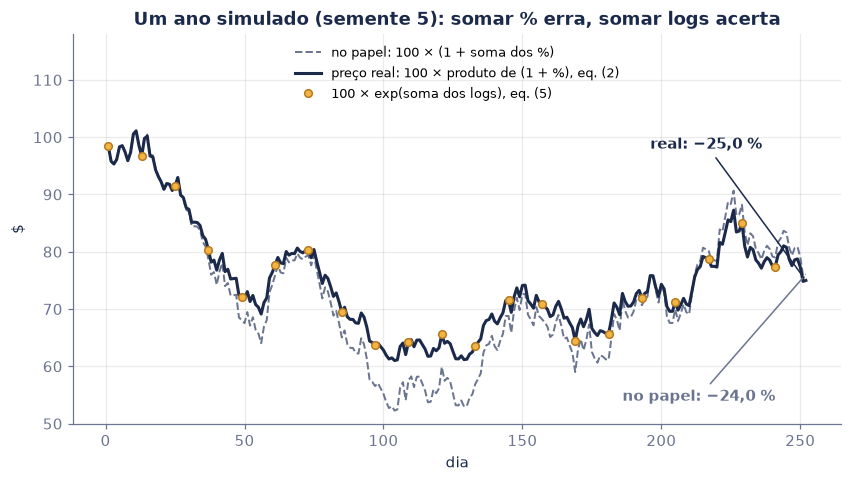

In [6]:
dias = np.arange(1, 253)
papel = 100 * (1 + cum_pct)                         # o preço "no papel": somando os %
via_log = 100 * np.exp(np.cumsum(log))              # (5): o preço refeito só com a soma dos logs
assert np.allclose(via_log, preco)
mostra(pd.DataFrame({"conta": ["soma dos 252 retornos simples", "soma dos 252 retornos log", "exp(Σ log) − 1, eq. (5)", "retorno real do ano (preço final / 100 − 1)"],
                     "resultado": [pc(soma_pct, 2), br(log.sum(), 4), pc(soma_log, 2), pc(real, 2)]}))
print(f"preço final {usd(preco[-1])}; mínimo {usd(preco.min())} no dia {preco.argmin() + 1}; máximo {usd(preco.max())} no dia {preco.argmax() + 1}")
print(f"desvio-padrão dos 252 dias sorteados: {pc(pct.std(), 2)} (o parâmetro é 2 %)")

fig, ax = plt.subplots()
ax.plot(dias, papel, color=GREY, ls="--", lw=1.3, label="no papel: 100 × (1 + soma dos %)")
ax.plot(dias, preco, color=NAVY, lw=2, label="preço real: 100 × produto de (1 + %), eq. (2)")
ax.plot(dias[::12], via_log[::12], "o", color=AMBER, ms=5, mec=GOLD, label="100 × exp(soma dos logs), eq. (5)")
ax.annotate(f"no papel: {pc(soma_pct)}", (252, papel[-1]), (186, 54), color=GREY, weight="bold", arrowprops=dict(arrowstyle="-", color=GREY))
ax.annotate(f"real: {pc(real)}", (252, preco[-1]), (196, 98), color=NAVY, weight="bold", arrowprops=dict(arrowstyle="-", color=NAVY))
ax.set(title="Um ano simulado (semente 5): somar % erra, somar logs acerta", xlabel="dia", ylabel="$", ylim=(50, 118))
ax.legend(frameon=False, loc="upper center", fontsize=8.5); plt.show()

## 4. Por que a soma dos % erra, e para que lado — eq. (6)

Expanda o log em série de Taylor em torno de zero:

$$
\ln(1+R) = R - \frac{R^2}{2} + \frac{R^3}{3} - \cdots
\quad\Longrightarrow\quad
\sum_t r_t \approx \sum_t R_t - \frac{1}{2}\sum_t R_t^2 \tag{6}
$$

A soma dos % fica **acima** da soma dos logs por cerca de $\tfrac12 \sum R_t^2$, o **arrasto da volatilidade**: ele não depende da direção dos dias, só do tamanho. Com 252 dias de 2 %, o esperado é $\tfrac12 \times 252 \times 0{,}02^2 = 5{,}04$ pontos. Depois, converter a soma dos logs de volta para % (eq. 5) **sobe** o número, porque $e^{y} - 1 \ge y$ para todo $y$. São dois efeitos com sinais opostos, e o erro da soma dos % é a diferença entre eles:

passo,valor (pontos de %)
soma dos % diários,"−23,96"
"− ½ Σ R², eq. (6)","−4,83"
+ ⅓ Σ R³,"0,01"
ordem ≥ 4,"−0,00"
= soma dos logs,"−28,78"
+ conversão: e^y − 1 − y,"3,77"
= retorno real,"−25,01"


arrasto realizado ½ Σ R² = 4,83 pontos; esperado ½ σ² T = ½ × 0,02² × 252 = 5,04 pontos
o erro da soma dos %: 1,05 ponto = arrasto 4,83 − conversão 3,77 (± termos de ordem 3+)
real − soma dos %: exato −1,05 · 2ª ordem ½[(Σ r)² − Σ R²] = −0,69 · com a 3ª ordem −1,08 (pontos)
tendência |Σ r| = 0,288 contra volatilidade realizada √(Σ R²) = 0,311: tendência menor, a soma dos % exagera


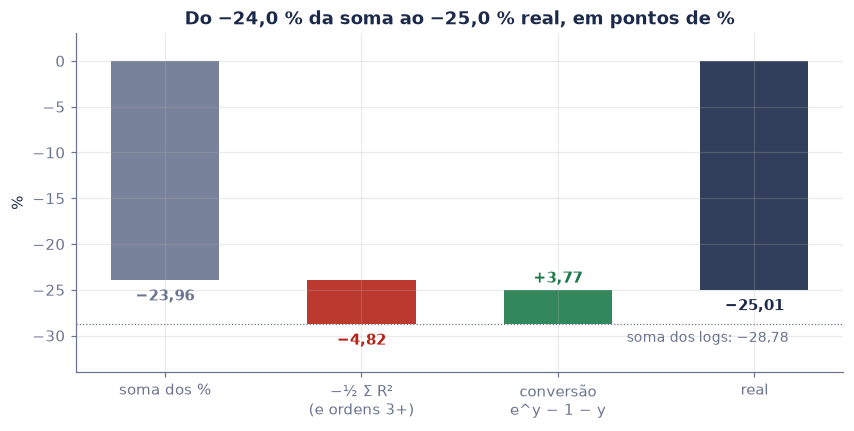

In [7]:
arrasto = 0.5 * (pct ** 2).sum()                     # ½ Σ R²
cubo = (pct ** 3).sum() / 3                          # ⅓ Σ R³
resto = log.sum() - (soma_pct - arrasto + cubo)      # termos de ordem 4 em diante
conversao = np.expm1(log.sum()) - log.sum()          # e^y − 1 − y ≥ 0
passos_ = [("soma dos % diários", soma_pct), ("− ½ Σ R², eq. (6)", -arrasto), ("+ ⅓ Σ R³", cubo), ("ordem ≥ 4", resto),
           ("= soma dos logs", log.sum()), ("+ conversão: e^y − 1 − y", conversao), ("= retorno real", real)]
mostra(pd.DataFrame({"passo": [s for s, _ in passos_], "valor (pontos de %)": [br(100 * v, 2) for _, v in passos_]}))
assert abs(soma_pct - arrasto + cubo + resto - log.sum()) < 1e-15 and abs(log.sum() + conversao - real) < 1e-12
assert abs(log.sum() - (soma_pct - arrasto)) < 1e-3                    # (6) acerta a soma dos logs em menos de 0,1 ponto
print(f"arrasto realizado ½ Σ R² = {br(100 * arrasto, 2)} pontos; esperado ½ σ² T = ½ × 0,02² × 252 = {br(100 * 0.5 * 0.02 ** 2 * 252, 2)} pontos")
print(f"o erro da soma dos %: {br(100 * (soma_pct - real), 2)} ponto = arrasto {br(100 * arrasto, 2)} − conversão {br(100 * conversao, 2)} (± termos de ordem 3+)")
o2 = 0.5 * (log.sum() ** 2 - (pct ** 2).sum())                      # real − soma dos %, até a 2ª ordem
o3 = o2 + log.sum() ** 3 / 6 + (pct ** 3).sum() / 3                  # + 3ª ordem
print(f"real − soma dos %: exato {br(100 * (real - soma_pct), 2)} · 2ª ordem ½[(Σ r)² − Σ R²] = {br(100 * o2, 2)} · com a 3ª ordem {br(100 * o3, 2)} (pontos)")
print(f"tendência |Σ r| = {br(abs(log.sum()), 3)} contra volatilidade realizada √(Σ R²) = {br(math.sqrt((pct ** 2).sum()), 3)}: tendência menor, a soma dos % exagera")

fig, ax = plt.subplots(figsize=(9, 4))
nomes = ["soma dos %", "−½ Σ R²\n(e ordens 3+)", "conversão\ne^y − 1 − y", "real"]
base, alt, cores = [0, soma_pct, log.sum(), 0], [soma_pct, -arrasto + cubo + resto, conversao, real], [GREY, RED, GREEN, NAVY]
for i, (b, h, c) in enumerate(zip(base, alt, cores)):
    ax.bar(i, 100 * h, bottom=100 * b, color=c, width=0.55, alpha=0.9)
    ax.text(i, 100 * (b + h) + (0.8 if h > 0 else -2.2), ("+" if h > 0 else "") + br(100 * h, 2), ha="center", color=c, weight="bold")
ax.axhline(100 * log.sum(), color=GREY, lw=0.8, ls=":"); ax.text(2.35, 100 * log.sum() - 1.9, f"soma dos logs: {br(100 * log.sum(), 2)}", ha="left", color=GREY, fontsize=9)
ax.set_xticks(range(4)); ax.set_xticklabels(nomes)
ax.set(title="Do −24,0 % da soma ao −25,0 % real, em pontos de %", ylabel="%", ylim=(-34, 3)); plt.show()

**Leitura.** Neste ano, o arrasto (−4,83 pontos) ganhou da conversão (+3,77 pontos), e a soma dos % ficou 1 ponto **acima** do real. Num ano de tendência forte e volatilidade baixa, a conversão ganha e a soma dos % fica **abaixo** do real. A soma dos % erra para os dois lados; a soma dos logs, pela eq. (5), nunca erra. A nota técnica transforma isso numa regra: a soma dos % exagera quando a tendência do ano é menor que a sua volatilidade realizada, e subestima quando é maior. Na seção 8, o Ibovespa mostra os dois casos.

## 5. Dias pequenos, dias grandes

Pela eq. (6), num dia pequeno os dois retornos quase coincidem: +1 % é 0,0100 em retorno simples e $\ln 1{,}01 = 0{,}00995$ em log. A diferença relativa é de cerca de $R/2$: meio por cento de um por cento. Com movimentos grandes, ela explode, e no limite de −100 % o log vai a **menos infinito**: perder tudo não tem volta em nenhuma escala.

retorno simples,retorno log (4),simples − log
−100 %,−∞,+∞
−90 %,"−2,30259","1,40259"
−50 %,"−0,69315","0,19315"
−20 %,"−0,22314","0,02314"
−10 %,"−0,10536","0,00536"
−1 %,"−0,01005","0,00005"
+1 %,"0,00995","0,00005"
+10 %,"0,09531","0,00469"
+20 %,"0,18232","0,01768"
+50 %,"0,40547","0,09453"


o arrasto esperado cresce com o tempo, ½ σ² T com σ = 2 % ao dia: 1 dias: 0,02 pontos · 21 dias: 0,42 pontos · 63 dias: 1,26 pontos · 252 dias: 5,04 pontos · 2520 dias: 50,40 pontos


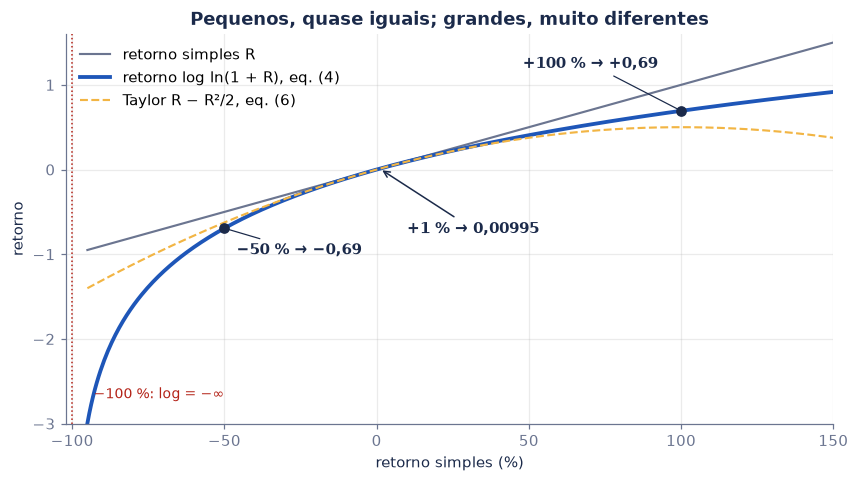

In [8]:
xs_ = np.array([-1.0, -0.90, -0.50, -0.20, -0.10, -0.01, 0.01, 0.10, 0.20, 0.50, 1.0, 9.0])
with np.errstate(divide="ignore"):
    lx = np.log1p(xs_)
mostra(pd.DataFrame({"retorno simples": [pcs(x, 0) for x in xs_], "retorno log (4)": [("−∞" if np.isinf(v) else br(v, 5)) for v in lx],
                     "simples − log": [("+∞" if np.isinf(v) else br(x - v, 5)) for x, v in zip(xs_, lx)]}))
assert round(float(np.log1p(0.01)), 5) == 0.00995 and np.isneginf(lx[0])
T = np.array([1, 21, 63, 252, 2520])
print("o arrasto esperado cresce com o tempo, ½ σ² T com σ = 2 % ao dia:", " · ".join(f"{t} dias: {br(100 * 0.5 * 0.02 ** 2 * t, 2)} pontos" for t in T))

fig, ax = plt.subplots()
x = np.linspace(-0.95, 1.5, 400)
ax.plot(100 * x, x, color=GREY, lw=1.4, label="retorno simples R")
ax.plot(100 * x, np.log1p(x), color=BLUE, lw=2.5, label="retorno log ln(1 + R), eq. (4)")
ax.plot(100 * x, x - x ** 2 / 2, color=AMBER, lw=1.4, ls="--", label="Taylor R − R²/2, eq. (6)")
for v, txt_, xy_txt in ((-0.5, "−50 % → −0,69", (-46, -1.0)), (1.0, "+100 % → +0,69", (48, 1.2))):
    ax.scatter([100 * v], [np.log1p(v)], color=NAVY, zorder=3)
    ax.annotate(txt_, (100 * v, np.log1p(v)), xy_txt, color=NAVY, weight="bold", arrowprops=dict(arrowstyle="-", color=NAVY, lw=0.8))
ax.annotate("+1 % → 0,00995", (1, 0.00995), (10, -0.75), color=NAVY, weight="bold", arrowprops=dict(arrowstyle="->", color=NAVY))
ax.axvline(-100, color=RED, lw=1, ls=":"); ax.text(-93, -2.7, "−100 %: log = −∞", color=RED, fontsize=9)
ax.set(title="Pequenos, quase iguais; grandes, muito diferentes", xlabel="retorno simples (%)", ylabel="retorno", ylim=(-3, 1.6), xlim=(-102, 150))
ax.legend(frameon=False, loc="upper left"); plt.show()

## 6. Por que os quants amam o log — eq. (7)

1. **Somam no tempo** (eq. 5). O retorno de um ano é a soma dos retornos log dos dias.
2. **O preço nunca fica negativo.** Pela eq. (5), $P_T = P_0\,e^{\sum r_t}$, e a exponencial é sempre positiva, qualquer que seja a soma.
3. **O modelo clássico de uma ação.** Se os retornos log diários são independentes e normais, com média $m$ e variância $s^2$, a soma de $T$ deles é normal com média $mT$ e variância $s^2T$, e o preço é **lognormal**:

$$
\ln\frac{P_T}{P_0} \sim N\!\left(mT,\; s^2T\right)
\quad\Longrightarrow\quad
\text{mediana}(P_T) = P_0\,e^{mT}, \qquad \mathbb{E}[P_T] = P_0\,e^{mT + s^2T/2} \tag{7}
$$

A média fica acima da mediana: a distribuição do preço tem cauda longa para cima. Detalhe honesto: o código do vídeo sorteia **retornos simples** normais (média 0, desvio 2 %). Então o preço esperado é exatamente \$100, mas o log diário tem média de cerca de $-\sigma^2/2 = -0{,}0002$ e o preço **mediano** no fim do ano fica perto de $100\,e^{-0{,}0504} \approx$ \$95. Sorteando 50.000 anos com os mesmos parâmetros (outra semente):

preço final: média $99,86 (teoria: $100,00) · mediana $95,20 (teoria pela (7): $95,08)
o ano do vídeo (−25,0 %, $75) está no percentil 22,8: 1 ano em 4,4
soma dos logs no ano: média −0,0515, desvio 0,3167 (teoria σ√T = 0,3175)
menor preço final entre 50.000 anos: $27,19 > 0  ·  linha 'no papel' abaixo de zero em 0,07 % dos anos


com 5 % ao dia: 'no papel' abaixo de zero em 10,1 % dos anos; preço real mínimo $1,79 > 0
teoria (soma dos % ~ normal): P(Σ R < −1) = Φ(−1/(σ√252)) = 0,08 % com σ = 2 % e 10,4 % com σ = 5 %


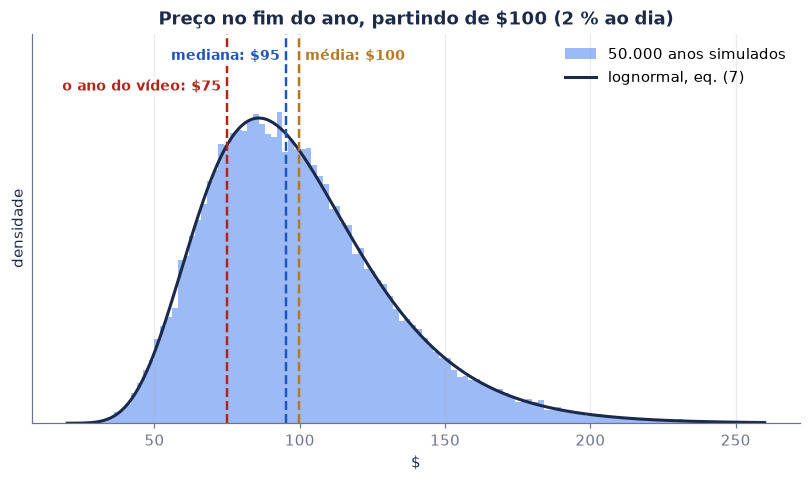

In [9]:
sim = np.random.default_rng(2026)
N, lotes = 50_000, 10
somas_log, somas_pct = [], []
for _ in range(lotes):                                  # em lotes, para não ocupar memória
    X = sim.normal(0, 0.02, (N // lotes, 252))
    somas_log.append(np.log1p(X).sum(1)); somas_pct.append(X.sum(1))
somas_log, somas_pct = np.concatenate(somas_log), np.concatenate(somas_pct)
final = 100 * np.exp(somas_log)                          # (5)
m_dia = -0.02 ** 2 / 2 - 3 * 0.02 ** 4 / 4               # E[ln(1 + R)] para R ~ N(0; 2 %), pela série (6) até a 4ª ordem
print(f"preço final: média {usd(final.mean())} (teoria: $100,00) · mediana {usd(np.median(final))} (teoria pela (7): {usd(100 * np.exp(252 * m_dia))})")
print(f"o ano do vídeo (−25,0 %, $75) está no percentil {br(100 * (final <= preco[-1]).mean(), 1)}: 1 ano em {br(1 / (final <= preco[-1]).mean(), 1)}")
print(f"soma dos logs no ano: média {br(somas_log.mean(), 4)}, desvio {br(somas_log.std(), 4)} (teoria σ√T = {br(0.02 * math.sqrt(252), 4)})")
print(f"menor preço final entre {br(N, 0)} anos: {usd(final.min())} > 0  ·  linha 'no papel' abaixo de zero em {br(100 * (somas_pct < -1).mean(), 2)} % dos anos")
X5 = np.random.default_rng(7).normal(0, 0.05, (20_000, 252))
print(f"com 5 % ao dia: 'no papel' abaixo de zero em {br(100 * (X5.sum(1) < -1).mean(), 1)} % dos anos; preço real mínimo {usd(100 * np.prod(1 + X5, 1).min())} > 0")
Phi = lambda x: 0.5 * math.erfc(-x / math.sqrt(2))                  # normal acumulada, sem scipy
print(f"teoria (soma dos % ~ normal): P(Σ R < −1) = Φ(−1/(σ√252)) = {br(100 * Phi(-1 / (0.02 * math.sqrt(252))), 2)} % com σ = 2 % e {br(100 * Phi(-1 / (0.05 * math.sqrt(252))), 1)} % com σ = 5 %")
assert abs(final.mean() / 100 - 1) < 0.01 and 94 < np.median(final) < 97 and final.min() > 0

fig, ax = plt.subplots()
ax.hist(final, bins=np.linspace(20, 260, 121), density=True, color=LIGHT, alpha=0.6, label="50.000 anos simulados")
mu_, sd_ = somas_log.mean(), somas_log.std()
xx = np.linspace(20, 260, 400)
ax.plot(xx, np.exp(-(np.log(xx / 100) - mu_) ** 2 / (2 * sd_ ** 2)) / (xx * sd_ * math.sqrt(2 * math.pi)), color=NAVY, lw=2, label="lognormal, eq. (7)")
caixa = dict(fc="white", ec="none", alpha=0.85, pad=1.5)
for v, c, s, y_, ha in ((np.median(final), BLUE, "mediana", 0.0166, "right"), (final.mean(), GOLD, "média", 0.0166, "left"), (preco[-1], RED, "o ano do vídeo", 0.0152, "right")):
    ax.axvline(v, color=c, lw=1.6, ls="--")
    ax.text(v + (2 if ha == "left" else -2), y_, f"{s}: {usd(v, 0)}", color=c, weight="bold", fontsize=9, ha=ha, bbox=caixa)
ax.set(title="Preço no fim do ano, partindo de $100 (2 % ao dia)", xlabel="$", ylabel="densidade", yticks=[], ylim=(0, 0.0178)); ax.legend(frameon=False); plt.show()

**Leitura.** A média de \$100 é o que se espera de uma ação sem tendência, mas o **ano típico** termina em uns \$95: metade dos anos termina abaixo disso. A diferença é o arrasto da eq. (6) agindo na mediana, não na média. O ano do vídeo, com −25 %, não é azar extremo: acontece em mais de 1 ano a cada 5. E a linha "no papel" é mais que imprecisa: com volatilidade alta ela fica negativa, coisa que um preço não faz.

## 7. Entre ativos, quem soma é o retorno simples — eq. (8)

O log soma no **tempo**. Entre **ativos**, numa mesma data, quem soma é o simples. Uma carteira com pesos $w_i$ (somando 1) vale, no fim do período, $\sum_i w_i\,(1+R_i)$ por real investido, então

$$
R_p = \sum_i w_i\,R_i, \qquad\text{mas}\qquad r_p = \ln\!\Big(\sum_i w_i\,e^{r_i}\Big) \;\ge\; \sum_i w_i\,r_i \tag{8}
$$

A desigualdade é a de Jensen (o log é côncavo): a média ponderada dos logs **subestima** o retorno log da carteira. Metade em A (+50 %) e metade em B (−50 %): a carteira fica onde estava; a média dos logs diz −13,4 %.

In [10]:
acoes = pd.read_csv("dados/acoes_b3.csv", parse_dates=["data"]).set_index("data")
nomes_ = [c for c in acoes.columns if c != "IBOV"]
print(f"{len(nomes_)} ações da B3 + IBOV, de {acoes.index.min():%d/%m/%Y} a {acoes.index.max():%d/%m/%Y} ({len(acoes)} pregões), preços ajustados por proventos")

ab = np.array([0.5, -0.5])
print(f"50/50 em +50 % e −50 %: carteira (8) {pcs(ab.mean(), 1)}  ·  média dos logs convertida {pcs(np.expm1(np.log1p(ab).mean()), 1)}")
assert ab.mean() == 0 and round(100 * np.expm1(np.log1p(ab).mean()), 1) == -13.4

fim24, fim25 = acoes.loc[:"2024-12-31"].index[-1], acoes.loc[:"2025-12-31"].index[-1]
R25 = acoes.loc[fim25, nomes_] / acoes.loc[fim24, nomes_] - 1
cart = R25.mean()                                                   # (8) com pesos iguais
media_log = np.expm1(np.log1p(R25).mean())
print(f"carteira de pesos iguais nas {len(nomes_)} ações, comprada em {fim24:%d/%m/%Y} e vendida em {fim25:%d/%m/%Y}:")
print(f"   pela eq. (8): {pc(cart, 2)}   ·   média dos logs convertida: {pc(media_log, 2)}   ·   erro: {br(100 * (cart - media_log), 2)} pontos")
print(f"   em log: ln(1 + carteira) − média dos logs = {br(math.log1p(cart) - np.log1p(R25).mean(), 4)}; ½ × variância dos logs entre as ações = {br(0.5 * np.log1p(R25).var(ddof=0), 4)}")
print(f"   a melhor: {R25.idxmax()} {pcs(R25.max(), 1)}; a pior: {R25.idxmin()} {pcs(R25.min(), 1)}; Ibovespa no período: {pcs(acoes.loc[fim25, 'IBOV'] / acoes.loc[fim24, 'IBOV'] - 1, 1)}")
assert np.isclose((1 + R25).mean() - 1, cart) and media_log < cart

38 ações da B3 + IBOV, de 02/01/2015 a 09/10/2026 (2923 pregões), preços ajustados por proventos
50/50 em +50 % e −50 %: carteira (8) 0,0 %  ·  média dos logs convertida −13,4 %
carteira de pesos iguais nas 38 ações, comprada em 30/12/2024 e vendida em 30/12/2025:
   pela eq. (8): 31,33 %   ·   média dos logs convertida: 27,44 %   ·   erro: 3,88 pontos
   em log: ln(1 + carteira) − média dos logs = 0,0300; ½ × variância dos logs entre as ações = 0,0322
   a melhor: CYRE3 +97,8 %; a pior: CSAN3 −34,8 %; Ibovespa no período: +34,0 %


**Leitura.** A regra de bolso do quant: **log soma no tempo, simples soma entre ativos**. Para o retorno de uma carteira num período, use simples com pesos (eq. 8); para encadear períodos, use log (eq. 5). Misturar as duas coisas é um dos erros mais comuns em planilha de gestão: a média dos logs de 38 ações não é o retorno de quem comprou as 38.

## 8. Dado real: o Ibovespa ano a ano desde 1995

A mesma conta do vídeo, agora com o Ibovespa de verdade. Para cada ano: a soma dos retornos simples diários, a soma dos logs convertida pela eq. (5) e o retorno do ano (fechamento do ano sobre o do ano anterior). Antes, a qualidade do dado: datas repetidas, buracos e os maiores saltos diários.

In [11]:
ibov = pd.read_csv("dados/ibovespa.csv", parse_dates=["data"]).set_index("data")["ibov"]
cdi = pd.read_csv("dados/cdi_diario.csv", parse_dates=["data"]).set_index("data")["cdi_pct_ad"] / 100
assert not ibov.index.duplicated().any() and ibov.index.is_monotonic_increasing and (ibov > 0).all()
Ri = ibov.pct_change().dropna(); ri = np.log1p(Ri)
print(f"Ibovespa: {len(ibov)} fechamentos de {ibov.index[0]:%d/%m/%Y} (base) a {ibov.index[-1]:%d/%m/%Y}; {len(Ri)} retornos diários")
print(f"maior intervalo entre pregões: {int(ibov.index.to_series().diff().dt.days.max())} dias corridos (carnaval)")
ext = pd.concat([Ri.nsmallest(4), Ri.nlargest(4)]).sort_index()
print("os maiores saltos diários (todos são eventos reais):", " · ".join(f"{d:%d/%m/%Y} {pcs(v, 1)}" for d, v in ext.items()))

Ibovespa: 7876 fechamentos de 29/12/1994 (base) a 16/10/2026; 7875 retornos diários
maior intervalo entre pregões: 6 dias corridos (carnaval)
os maiores saltos diários (todos são eventos reais): 10/03/1995 +25,6 % · 27/10/1997 −15,0 % · 10/09/1998 −15,8 % · 15/09/1998 +18,7 % · 15/01/1999 +33,4 % · 13/10/2008 +14,7 % · 12/03/2020 −14,8 % · 16/03/2020 −13,9 %


In [12]:
anos = []
for a in range(1995, 2027):
    Ra, ra = Ri.loc[str(a)], ri.loc[str(a)]
    base_ = ibov.loc[:f"{a - 1}-12-31"].iloc[-1]
    anos.append({"ano": a, "dias": len(Ra), "soma_pct": Ra.sum(), "soma_log": ra.sum(), "via_log": np.expm1(ra.sum()),
                 "real": ibov.loc[str(a)].iloc[-1] / base_ - 1, "lacuna": Ra.sum() - ra.sum(), "meio_R2": 0.5 * (Ra ** 2).sum(),
                 "vol": Ra.std() * math.sqrt(252)})
A = pd.DataFrame(anos).set_index("ano")
assert np.allclose(A.via_log, A.real, atol=1e-10)                 # (5) é exata, ano a ano
mostra(pd.DataFrame({"ano": [str(a) + ("*" if a == 2026 else "") for a in A.index], "pregões": A.dias,
                     "soma dos % diários": [pc(v) for v in A.soma_pct], "exp(Σ log) − 1": [pc(v) for v in A.via_log],
                     "retorno do ano": [pc(v) for v in A.real], "soma dos % − real (pontos)": [br(100 * v, 1) for v in A.soma_pct - A.real],
                     "lacuna Σ R − Σ r": [br(100 * v, 2) for v in A.lacuna], "½ Σ R², eq. (6)": [br(100 * v, 2) for v in A.meio_R2],
                     "vol. anual": [pc(v, 0) for v in A.vol]}), "Ibovespa, 1995 a 2026 (* 2026 até 16/10)")

ano,pregões,soma dos % diários,exp(Σ log) − 1,retorno do ano,soma dos % − real (pontos),lacuna Σ R − Σ r,"½ Σ R², eq. (6)",vol. anual
1995,246,"14,7 %","−1,3 %","−1,3 %","16,0","15,99","16,49",58 %
1996,248,"52,0 %","63,8 %","63,8 %","−11,7","2,69","2,70",23 %
1997,249,"47,9 %","44,8 %","44,8 %","3,0","10,84","10,69",47 %
1998,247,"−24,6 %","−33,5 %","−33,5 %","8,9","16,19","16,23",58 %
1999,246,"103,6 %","151,9 %","151,9 %","−48,4","11,16","12,17",50 %
2000,248,"−6,0 %","−10,7 %","−10,7 %","4,7","5,32","5,31",33 %
2001,245,"−6,3 %","−11,0 %","−11,0 %","4,7","5,37","5,37",33 %
2002,249,"−13,3 %","−17,0 %","−17,0 %","3,7","5,33","5,32",33 %
2003,250,"71,0 %","97,3 %","97,3 %","−26,4","2,99","3,00",24 %
2004,249,"20,4 %","17,8 %","17,8 %","2,6","4,00","4,00",28 %


exp(Σ log) − 1 = retorno do ano em todos os 32 anos (diferença máxima 2.7e-15)
lacuna Σ R − Σ r contra ½ Σ R²: correlação 0,9991; maior distância 1,02 ponto (1999)
anos de maior lacuna: 1998: 16,2 pontos (vol 58 %) · 1995: 16,0 pontos (vol 58 %) · 2008: 13,5 pontos (vol 52 %) · 1999: 11,2 pontos (vol 50 %) · 1997: 10,8 pontos (vol 47 %)
a soma dos % ficou ACIMA do real em 19 anos e ABAIXO em 13
regra da nota (sinal de (Σ r)² − Σ R²) acerta o lado do erro em 30 de 32 anos; erra em 2005 (−0,2 ponto), 2008 (1,6 ponto)
   1995: soma dos % +14,7 % · real −1,3 %
   1999: soma dos % +103,6 % · real +151,9 %
   2003: soma dos % +71,0 % · real +97,3 %
   2008: soma dos % −39,6 % · real −41,2 %
   2020: soma dos % +12,8 % · real +2,9 %


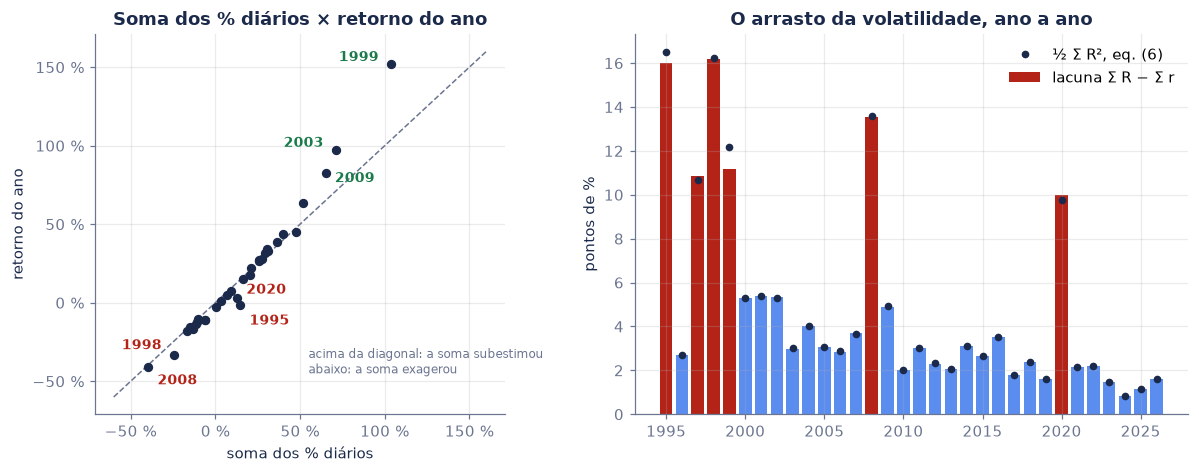

In [13]:
cor = np.corrcoef(A.lacuna, A.meio_R2)[0, 1]
regra = np.sign(A.real - A.soma_pct) == np.sign(A.soma_log ** 2 - 2 * A.meio_R2)   # tendência² contra volatilidade realizada²
print(f"exp(Σ log) − 1 = retorno do ano em todos os {len(A)} anos (diferença máxima {abs(A.via_log - A.real).max():.1e})")
print(f"lacuna Σ R − Σ r contra ½ Σ R²: correlação {br(cor, 4)}; maior distância {br(100 * (A.lacuna - A.meio_R2).abs().max(), 2)} ponto ({(A.lacuna - A.meio_R2).abs().idxmax()})")
print("anos de maior lacuna:", " · ".join(f"{a}: {br(100 * v, 1)} pontos (vol {pc(A.vol[a], 0)})" for a, v in A.lacuna.nlargest(5).items()))
print(f"a soma dos % ficou ACIMA do real em {(A.soma_pct > A.real).sum()} anos e ABAIXO em {(A.soma_pct < A.real).sum()}")
print(f"regra da nota (sinal de (Σ r)² − Σ R²) acerta o lado do erro em {regra.sum()} de {len(A)} anos; erra em", ", ".join(f"{a} ({br(100 * (A.soma_pct[a] - A.real[a]), 1)} ponto)" for a in A.index[~regra]))
for a in (1995, 1999, 2003, 2008, 2020):
    print(f"   {a}: soma dos % {pcs(A.soma_pct[a])} · real {pcs(A.real[a])}")
assert cor > 0.99 and (A.lacuna > 0).all()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1, 1.35]})
a1.plot([-0.6, 1.6], [-0.6, 1.6], color=GREY, ls="--", lw=1)
a1.scatter(A.soma_pct, A.real, color=NAVY, s=26, zorder=3)
desl = {1995: (6, -13), 1998: (-34, 4), 1999: (-34, 2), 2003: (-34, 2), 2008: (6, -11), 2009: (6, -6), 2020: (6, 3)}
for a, off in desl.items():
    a1.annotate(str(a), (A.soma_pct[a], A.real[a]), off, textcoords="offset points", color=RED if a in (1995, 1998, 2008, 2020) else GREEN, weight="bold", fontsize=9)
a1.set(title="Soma dos % diários × retorno do ano", xlabel="soma dos % diários", ylabel="retorno do ano")
a1.xaxis.set_major_formatter(lambda v, _: br(100 * v, 0) + " %"); a1.yaxis.set_major_formatter(lambda v, _: br(100 * v, 0) + " %")
a1.text(0.55, -0.45, "acima da diagonal: a soma subestimou\nabaixo: a soma exagerou", color=GREY, fontsize=8)
a2.bar(A.index, 100 * A.lacuna, color=[RED if v > 0.08 else LIGHT for v in A.lacuna], label="lacuna Σ R − Σ r")
a2.plot(A.index, 100 * A.meio_R2, "o", color=NAVY, ms=4, label="½ Σ R², eq. (6)")
a2.set(title="O arrasto da volatilidade, ano a ano", ylabel="pontos de %"); a2.legend(frameon=False)
plt.tight_layout(); plt.show()

**Leitura.** A eq. (5) reproduz o retorno de todos os anos, e a lacuna entre a soma dos % e a soma dos logs é o $\tfrac12\sum R^2$ da eq. (6), quase ponto por ponto. Os anos de lacuna grande são os de crise e volatilidade alta: 1998, 1995, 2008, 1999, 1997 e 2020. Em 1995, a soma dos % diários dizia +14,7 %, e o índice terminou o ano com −1,3 %. Em 1999, a soma dizia +103,6 %, e o índice subiu 151,9 %. A soma dos % erra para os dois lados, exatamente como a seção 4 previu.

## 9. Replicação: Hudson & Gregoriou (2015) — eq. (9)

Hudson e Gregoriou (2015) chamam atenção para um detalhe que muita pesquisa ignora: a **média** dos retornos log é sistematicamente menor que a média dos retornos simples, por um termo ligado à variância. Tomando a média da eq. (6) e usando $\overline{R^2} = s^2 + \bar R^2 \approx s^2$:

$$
\bar r \;\approx\; \bar R - \frac{s^2}{2} \tag{9}
$$

com $s^2$ a variância amostral dos retornos simples. A consequência prática é o título do artigo: **comparar** ativos pela média dos simples ou pela média dos logs pode dar ordens diferentes, porque ativos mais voláteis perdem mais na passagem de um para o outro. O teste abaixo usa as 38 ações da B3, de 2015 a 2026, em dados diários.

In [14]:
Ra_ = acoes[nomes_].pct_change().dropna()
ra_ = np.log1p(Ra_)
hg = pd.DataFrame({"R_med": Ra_.mean(), "r_med": ra_.mean(), "meio_s2": Ra_.var() / 2})
hg["dif"] = hg.R_med - hg.r_med
hg["total"] = acoes[nomes_].iloc[-1] / acoes[nomes_].iloc[0] - 1
hg["pos_R"] = hg.R_med.rank(ascending=False).astype(int); hg["pos_r"] = hg.r_med.rank(ascending=False).astype(int)
hg = hg.sort_values("R_med", ascending=False)
b = (hg.meio_s2 * hg.dif).sum() / (hg.meio_s2 ** 2).sum()      # inclinação de dif contra ½ s², sem intercepto
cor_hg = np.corrcoef(hg.meio_s2, hg.dif)[0, 1]
mostra(pd.DataFrame({"ação": hg.index, "média simples (% ao dia)": [br(100 * v, 3) for v in hg.R_med], "média log (% ao dia)": [br(100 * v, 3) for v in hg.r_med],
                     "diferença": [br(100 * v, 3) for v in hg.dif], "s²/2, eq. (9)": [br(100 * v, 3) for v in hg.meio_s2],
                     "posição pela simples": hg.pos_R, "posição pelo log": hg.pos_r, "retorno total no período": [pcs(v, 0) for v in hg.total]}),
       f"Médias diárias de {Ra_.index[0]:%d/%m/%Y} a {Ra_.index[-1]:%d/%m/%Y} ({len(Ra_)} dias)")

ação,média simples (% ao dia),média log (% ao dia),diferença,"s²/2, eq. (9)",posição pela simples,posição pelo log,retorno total no período
PRIO3,"0,254","0,171","0,083","0,088",1,1,+14.571 %
MGLU3,"0,154","0,064","0,090","0,092",2,13,+548 %
PETR4,"0,149","0,109","0,040","0,040",3,2,+2.288 %
BRAP4,"0,125","0,092","0,033","0,033",4,3,+1.384 %
SBSP3,"0,115","0,090","0,025","0,025",5,4,+1.275 %
B3SA3,"0,112","0,084","0,028","0,028",6,6,+1.053 %
WEGE3,"0,104","0,082","0,022","0,022",7,7,+995 %
VALE3,"0,101","0,067","0,034","0,034",8,11,+599 %
RENT3,"0,100","0,066","0,035","0,035",9,12,+579 %
EQTL3,"0,099","0,084","0,015","0,015",10,5,+1.080 %


In [15]:
def blocos(n, L, g):                    # índices de um bootstrap em blocos móveis de L dias
    st = g.integers(0, n - L + 1, int(np.ceil(n / L)))
    return (st[:, None] + np.arange(L)).ravel()[:n]

X_ = Ra_.values; g = np.random.default_rng(15); bs = []
for _ in range(1000):
    Xb = X_[blocos(len(X_), 21, g)]
    xb, yb = Xb.var(0, ddof=1) / 2, Xb.mean(0) - np.log1p(Xb).mean(0)
    bs.append((xb * yb).sum() / (xb ** 2).sum())
lo_b, hi_b = np.percentile(bs, [2.5, 97.5])
print(f"diferença das médias contra s²/2, nas {len(hg)} ações: inclinação {br(b, 3)} (IC 95 % por bootstrap em blocos de 21 dias: {br(lo_b, 3)} a {br(hi_b, 3)}); correlação {br(cor_hg, 4)}")
prev4 = (Ra_ ** 2).mean() / 2 - (Ra_ ** 3).mean() / 3 + (Ra_ ** 4).mean() / 4   # a série (6) até a 4ª ordem, em média
b4 = (prev4 * hg.dif.reindex(prev4.index)).sum() / (prev4 ** 2).sum()
print(f"com a série até a 4ª ordem (½ R² − ⅓ R³ + ¼ R⁴, em média) no lugar de s²/2: inclinação {br(b4, 3)}; assimetria média das ações (3º momento padronizado) {br(float(((Ra_ - Ra_.mean()) ** 3).mean().div(Ra_.std() ** 3).mean()), 2)}")
inv = sum((hg.R_med[i] - hg.R_med[j]) * (hg.r_med[i] - hg.r_med[j]) < 0 for k, i in enumerate(hg.index) for j in hg.index[k + 1:])
npar = len(hg) * (len(hg) - 1) // 2
print(f"posições que mudam do ranking pela média simples para o ranking pela média log: {(hg.pos_R != hg.pos_r).sum()} de {len(hg)}")
print(f"pares de ações cuja ordem se inverte: {inv} de {npar} ({br(100 * inv / npar, 1)} %)")
for t_ in ("MGLU3", "CSNA3", "USIM5", "BRKM5", "TAEE11", "EQTL3"):
    print(f"   {t_}: média simples {br(100 * hg.R_med[t_], 3)} % ao dia (posição {hg.pos_R[t_]}), média log {br(100 * hg.r_med[t_], 3)} % (posição {hg.pos_r[t_]}), "
          f"vol {pc(math.sqrt(2 * hg.meio_s2[t_] * 252), 0)} ao ano, total {pcs(hg.total[t_], 0)}")
pos_media = hg[hg.R_med > 0]; perdeu = pos_media[pos_media.total < 0]
print("média simples positiva e dinheiro perdido no período:", ", ".join(f"{t_} (média {br(100 * pos_media.R_med[t_], 3)} % ao dia, total {pcs(pos_media.total[t_], 0)})" for t_ in perdeu.index))
assert 0.95 < b < 1.02 and cor_hg > 0.99

diferença das médias contra s²/2, nas 38 ações: inclinação 0,987 (IC 95 % por bootstrap em blocos de 21 dias: 0,963 a 1,005); correlação 0,9994
com a série até a 4ª ordem (½ R² − ⅓ R³ + ¼ R⁴, em média) no lugar de s²/2: inclinação 0,997; assimetria média das ações (3º momento padronizado) 0,20


posições que mudam do ranking pela média simples para o ranking pela média log: 34 de 38
pares de ações cuja ordem se inverte: 101 de 703 (14,4 %)
   MGLU3: média simples 0,154 % ao dia (posição 2), média log 0,064 % (posição 13), vol 68 % ao ano, total +548 %
   CSNA3: média simples 0,095 % ao dia (posição 13), média log 0,028 % (posição 33), vol 58 % ao ano, total +125 %
   USIM5: média simples 0,084 % ao dia (posição 16), média log 0,023 % (posição 35), vol 56 % ao ano, total +96 %
   BRKM5: média simples 0,027 % ao dia (posição 38), média log −0,032 % (posição 38), vol 55 % ao ano, total −60 %
   TAEE11: média simples 0,081 % ao dia (posição 20), média log 0,071 % (posição 9), vol 22 % ao ano, total +695 %
   EQTL3: média simples 0,099 % ao dia (posição 10), média log 0,084 % (posição 5), vol 27 % ao ano, total +1.080 %
média simples positiva e dinheiro perdido no período: BRKM5 (média 0,027 % ao dia, total −60 %)


Ibovespa, 7875 dias: média simples × 252 = 17,2 % (erro-padrão 5,4 pontos); média log × 252 = 12,3 % (erro-padrão 5,5)
diferença = 4,86 pontos ao ano; s²/2 × 252 = 4,89; o que sobra (assimetria e caudas) = −0,035 ± 0,036
crescimento composto de fato: e^(média log × 252) − 1 = 13,1 % ao ano


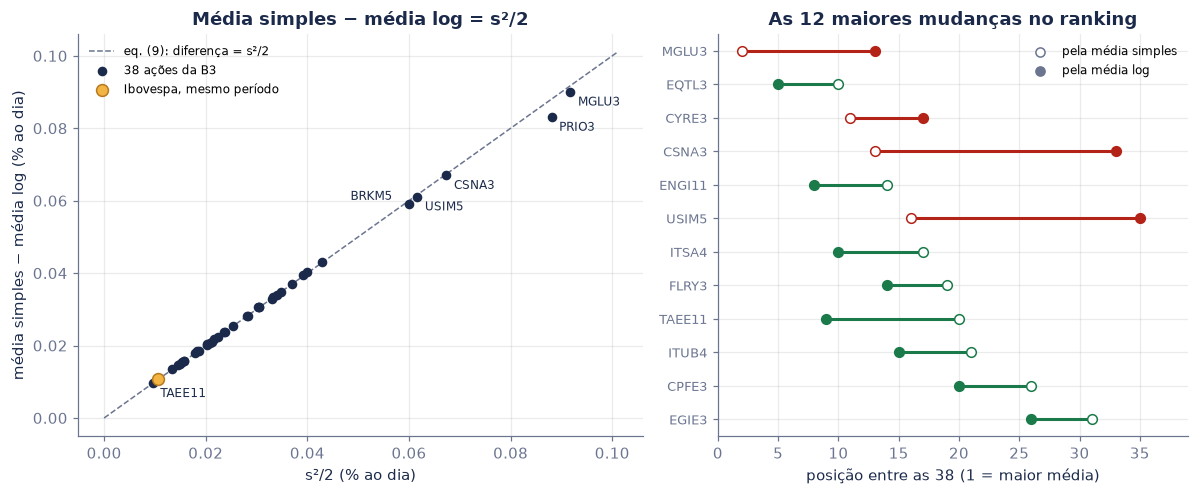

In [16]:
# O mesmo no Ibovespa de 1995 a 2026: quanto cada média é incerta, e quanto a diferença entre elas é
g2 = np.random.default_rng(21); Rv = Ri.values; est = []
for _ in range(2000):
    xb = Rv[blocos(len(Rv), 21, g2)]
    est.append((xb.mean(), np.log1p(xb).mean(), xb.mean() - np.log1p(xb).mean() - xb.var(ddof=1) / 2))
est = np.array(est) * 252
Rm, rm = Ri.mean() * 252, ri.mean() * 252
print(f"Ibovespa, {len(Ri)} dias: média simples × 252 = {pc(Rm)} (erro-padrão {br(100 * est[:, 0].std(), 1)} pontos); média log × 252 = {pc(rm)} (erro-padrão {br(100 * est[:, 1].std(), 1)})")
print(f"diferença = {br(100 * (Rm - rm), 2)} pontos ao ano; s²/2 × 252 = {br(100 * Ri.var() / 2 * 252, 2)}; o que sobra (assimetria e caudas) = {br(100 * (Rm - rm - Ri.var() / 2 * 252), 3)} ± {br(100 * est[:, 2].std(), 3)}")
print(f"crescimento composto de fato: e^(média log × 252) − 1 = {pc(np.expm1(rm))} ao ano")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
lim = 100 * hg.meio_s2.max() * 1.1
a1.plot([0, lim], [0, lim], color=GREY, ls="--", lw=1, label="eq. (9): diferença = s²/2")
a1.scatter(100 * hg.meio_s2, 100 * hg.dif, color=NAVY, s=28, zorder=3, label="38 ações da B3")
Ib_ = acoes["IBOV"].pct_change().dropna()
a1.scatter([100 * Ib_.var() / 2], [100 * (Ib_.mean() - np.log1p(Ib_).mean())], color=AMBER, edgecolor=GOLD, s=60, zorder=4, label="Ibovespa, mesmo período")
for t_, off in (("MGLU3", (5, -9)), ("PRIO3", (5, -9)), ("CSNA3", (5, -9)), ("USIM5", (5, -9)), ("BRKM5", (-38, 3)), ("TAEE11", (5, -9))):
    a1.annotate(t_, (100 * hg.meio_s2[t_], 100 * hg.dif[t_]), off, textcoords="offset points", fontsize=8, color=NAVY)
a1.set(title="Média simples − média log = s²/2", xlabel="s²/2 (% ao dia)", ylabel="média simples − média log (% ao dia)"); a1.legend(frameon=False, fontsize=8)
sel = hg.loc[(hg.pos_R - hg.pos_r).abs().sort_values(ascending=False).index[:12]].sort_values("pos_R")
for k, t_ in enumerate(sel.index):
    pR, pr = int(sel.pos_R[t_]), int(sel.pos_r[t_])
    c = RED if pr > pR else GREEN
    a2.plot([pR, pr], [k, k], color=c, lw=2, zorder=2)
    a2.scatter([pR], [k], facecolor="white", edgecolor=c, s=40, zorder=3); a2.scatter([pr], [k], color=c, s=40, zorder=3)
a2.scatter([], [], facecolor="white", edgecolor=GREY, label="pela média simples"); a2.scatter([], [], color=GREY, label="pela média log")
a2.set(title="As 12 maiores mudanças no ranking", xlabel="posição entre as 38 (1 = maior média)", yticks=range(len(sel)), xlim=(0, 39), ylim=(len(sel) - 0.5, -0.5))
a2.set_yticklabels(sel.index, fontsize=8.5); a2.legend(frameon=False, fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

**Leitura.** A eq. (9) passa no teste com folga: a diferença entre as médias é s²/2 quase ação por ação, com inclinação perto de 1. O efeito de Hudson e Gregoriou aparece no ranking: as ações mais voláteis caem muitas posições quando trocamos a média simples pela média log, e há ação com **média diária positiva que perdeu dinheiro** no período. No Ibovespa, a média simples anualizada é uns 5 pontos maior que a média log; a incerteza de cada média é maior que isso (o futuro da bolsa não se estima com precisão), mas a **diferença** entre as duas é medida com precisão: ela é a variância, não ruído.

## 10. Mesa de operações: o P&L em R\$ e a posição alavancada

**(a) O P&L de um long-short.** Uma mesa compra R\$ 10 milhões de ITUB4 e vende R\$ 10 milhões de BBDC4 no fim de 2025 e carrega a posição até 09/10/2026. O P&L de cada perna é o valor investido vezes o retorno **simples** da perna (eq. 1); o da posição é a soma das pernas (eq. 8, com pesos +1 e −1). Usar a diferença dos logs erra o resultado em reais.

In [17]:
N_ = 10_000_000
d0, d1 = fim25, acoes.index[-1]
Rl, Rs = acoes.loc[d1, "ITUB4"] / acoes.loc[d0, "ITUB4"] - 1, acoes.loc[d1, "BBDC4"] / acoes.loc[d0, "BBDC4"] - 1
pnl, pnl_log = N_ * (Rl - Rs), N_ * (math.log1p(Rl) - math.log1p(Rs))
print(f"{d0:%d/%m/%Y} → {d1:%d/%m/%Y}: ITUB4 {pcs(Rl)} · BBDC4 {pcs(Rs)}")
print(f"P&L pela eq. (1), perna a perna: {brl(N_ * Rl, 0)} − {brl(N_ * Rs, 0)} = {brl(pnl, 0)}")
print(f"P&L pela diferença dos logs: {brl(pnl_log, 0)}  →  erro de {brl(pnl - pnl_log, 0)} ({br(100 * (pnl - pnl_log) / pnl, 1)} % do P&L)")

30/12/2025 → 09/10/2026: ITUB4 +31,4 % · BBDC4 +24,2 %
P&L pela eq. (1), perna a perna: R$ 3.144.427 − R$ 2.422.967 = R$ 721.460
P&L pela diferença dos logs: R$ 564.509  →  erro de R$ 156.951 (21,8 % do P&L)


**(b) A posição alavancada, rebalanceada todo dia.** Uma mesa (ou um fundo alavancado) mantém exposição de **2 vezes** o capital no Ibovespa, financiando a outra metade a CDI, e ajusta a posição no fim de cada dia. O retorno diário é $2R_t - c_t$, com $c_t$ o CDI do dia. Ele **não** é o dobro do retorno do ano: aplicando a eq. (6) aos dois lados, a nota técnica mostra que o retorno log da posição com alavancagem $L$ perde $\tfrac12 L(L-1)\sum R_t^2$ em relação a $L$ vezes o retorno log do índice. O arrasto cresce com o **quadrado** da alavancagem.

In [18]:
fator_cdi = (1 + cdi).cumprod().shift(1).fillna(1.0)          # CDI acumulado até a abertura de cada dia útil
idx_cdi = fator_cdi.reindex(fator_cdi.index.union(ibov.index)).ffill().fillna(1.0).reindex(ibov.index)
cdi_i = idx_cdi.pct_change().reindex(Ri.index)                # CDI que correu entre dois pregões (inclui os dias sem pregão)
def alav(L, a):
    R_, c_ = Ri.loc[str(a)], cdi_i.loc[str(a)]
    real_ = np.prod(1 + L * R_ - (L - 1) * c_) - 1
    aprox = np.expm1(L * np.log1p(R_).sum() - (L - 1) * c_.sum() - 0.5 * L * (L - 1) * (R_ ** 2).sum())
    estat = L * (np.prod(1 + R_) - 1) - (L - 1) * (np.prod(1 + c_) - 1)   # 2× comprado uma vez, sem rebalancear
    return real_, aprox, estat
linhas = []
for a in (2008, 2019, 2020, 2025):
    r1, ap, es = alav(2, a)
    linhas.append({"ano": a, "Ibovespa": pcs(A.real[a]), "2× rebalanceado todo dia": pcs(r1), "aproximação da nota": pcs(ap),
                   "2× sem rebalancear": pcs(es), "vol. do Ibovespa": pc(A.vol[a], 0)})
mostra(pd.DataFrame(linhas))
r20 = alav(2, 2020)[0]
print(f"2020: Ibovespa {pcs(A.real[2020])}; 2× rebalanceado todo dia {pcs(r20)}")
pior = {L: (L * Ri - (L - 1) * cdi_i).min() for L in (2, 3, 5, 7)}
dia_pior = (7 * Ri - 6 * cdi_i).idxmin()
print(f"o pior dia ({dia_pior:%d/%m/%Y}, Ibovespa {pcs(Ri[dia_pior])}) com alavancagem L:", " · ".join(f"{L}×: {pcs(v)}" for L, v in pior.items()))
assert pior[7] < -1 and pior[5] > -1

ano,Ibovespa,2× rebalanceado todo dia,aproximação da nota,2× sem rebalancear,vol. do Ibovespa
2008,"−41,2 %","−76,6 %","−76,6 %","−94,8 %",52 %
2019,"+31,9 %","+59,1 %","+59,1 %","+57,9 %",18 %
2020,"+2,9 %","−16,8 %","−15,3 %","+3,0 %",45 %
2025,"+34,0 %","+53,4 %","+53,4 %","+53,6 %",15 %


2020: Ibovespa +2,9 %; 2× rebalanceado todo dia −16,8 %
o pior dia (10/09/1998, Ibovespa −15,8 %) com alavancagem L: 2×: −31,7 % · 3×: −47,6 % · 5×: −79,5 % · 7×: −111,3 %


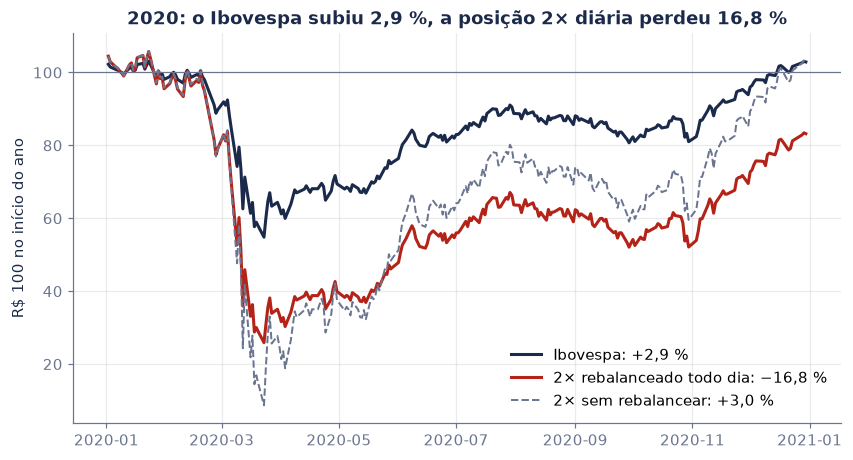

In [19]:
R0, c0 = Ri.loc["2020"], cdi_i.loc["2020"]
t_ = R0.index
fig, ax = plt.subplots()
ax.plot(t_, 100 * np.cumprod(1 + R0), color=NAVY, lw=2, label=f"Ibovespa: {pcs(A.real[2020])}")
ax.plot(t_, 100 * np.cumprod(1 + 2 * R0 - c0), color=RED, lw=2, label=f"2× rebalanceado todo dia: {pcs(r20)}")
ax.plot(t_, 100 * (2 * np.cumprod(1 + R0) - np.cumprod(1 + c0)), color=GREY, lw=1.3, ls="--", label=f"2× sem rebalancear: {pcs(alav(2, 2020)[2])}")
ax.axhline(100, color=GREY, lw=0.8)
ax.set(title=f"2020: o Ibovespa subiu {pc(A.real[2020])}, a posição 2× diária perdeu {pc(-r20)}", ylabel="R$ 100 no início do ano")
ax.legend(frameon=False, loc="lower right"); plt.show()

**Leitura.** Em 2020, o índice terminou o ano com +2,9 %, e a posição 2× rebalanceada todo dia perdeu 16,8 %: com 45 % de vol, o arrasto comeu a posição. A aproximação da nota dá −15,3 %; o resto vem dos termos de ordem 3 em diante, que pesam nos dias extremos de março. Em 2019 e 2025, anos de tendência e vol baixa, alavancar todo dia ou uma vez só dá quase o mesmo. Em 2008, o rebalanceamento diário cortou a exposição na descida e perdeu 76,6 %, contra 94,8 % da posição sem rebalancear. Para a mesa: **P&L em reais sai de retorno simples, perna a perna**; o log serve para acumular no tempo, não para somar posições.

**(c) Quando o log engana.** No dia 10/09/1998, o Ibovespa caiu 15,8 %. Com alavancagem de 7×, a posição perdeu mais que o capital: o retorno simples passou de −100 %, e o retorno log ($\ln$ de um número negativo) simplesmente não existe. O mesmo vale para uma posição vendida ou um long-short sem capital líquido: o log pressupõe que o valor da posição fica positivo.

## 11. Para o investidor

**(a) "Média de 1 % ao mês".** Um fundo que anuncia a média aritmética dos retornos mensais está anunciando $\bar R$. O que vai para o seu bolso é a taxa composta, $e^{\bar r} - 1$, e pela eq. (9) ela é menor por cerca de $s^2/2$. O Ibovespa, de 1995 a 2026:

In [20]:
Mi = ibov.resample("ME").last().pct_change().dropna()
Ai = ibov.resample("YE").last().pct_change().dropna().loc["1995":"2025"]       # só anos completos
geo_m, geo_a = np.expm1(np.log1p(Mi).mean()), np.expm1(np.log1p(Ai).mean())
print(f"mensal ({len(Mi)} meses): média aritmética {pc(Mi.mean(), 2)} · composta {pc(geo_m, 2)} · desvio {pc(Mi.std(), 2)} · eq. (9): {pc(Mi.mean() - Mi.var() / 2, 2)}")
print(f"anual (1995–2025, {len(Ai)} anos): média aritmética {pc(Ai.mean(), 1)} · composta (CAGR) {pc(geo_a, 1)}")
print(f"R$ 100 no fim de 1994 viraram {brl(100 * ibov.iloc[-1] / ibov.iloc[0])} em 16/10/2026; a 'média' de {pc(Mi.mean(), 2)} ao mês daria {brl(100 * (1 + Mi.mean()) ** len(Mi))}")
fundo = [(s, (1 + 0.01 - s ** 2 / 2) ** 12 - 1) for s in (0.0, 0.02, 0.05, 0.08)]
mostra(pd.DataFrame({"desvio mensal": [pc(s, 0) for s, _ in fundo], "taxa composta ao mês ≈ 1 % − s²/2": [pc(0.01 - s ** 2 / 2, 2) for s, _ in fundo],
                     "em 12 meses": [pc(v, 1) for _, v in fundo]}), "Um fundo com média aritmética de 1 % ao mês")
assert round(100 * Mi.mean(), 2) == 1.34 and round(100 * geo_m, 2) == 1.01

mensal (382 meses): média aritmética 1,34 % · composta 1,01 % · desvio 7,92 % · eq. (9): 1,02 %
anual (1995–2025, 31 anos): média aritmética 18,1 % · composta (CAGR) 12,4 %
R$ 100 no fim de 1994 viraram R$ 4.718,30 em 16/10/2026; a 'média' de 1,34 % ao mês daria R$ 15.951,25


desvio mensal,taxa composta ao mês ≈ 1 % − s²/2,em 12 meses
0 %,"1,00 %","12,7 %"
2 %,"0,98 %","12,4 %"
5 %,"0,88 %","11,0 %"
8 %,"0,68 %","8,5 %"


**(b) O CDI de cada dia.** O CDI é divulgado em % ao dia útil, e o rendimento acumulado é o **produto** dos fatores diários (eq. 2). Somar as taxas diárias dá, pela eq. (6), praticamente a taxa **contínua** $\ln(1 + \text{taxa do período})$, e não a taxa do período.

In [21]:
u = cdi.loc["2025-10-17":"2026-10-16"]
prod_u, soma_u = np.prod(1 + u) - 1, u.sum()
print(f"12 meses até 16/10/2026 ({len(u)} dias úteis): produto dos fatores {pc(prod_u, 2)} · soma das taxas {pc(soma_u, 2)} · ln(1 + {pc(prod_u, 2)}) = {pc(math.log1p(prod_u), 2)}")
print(f"R$ 100.000 no CDI: {brl(1e5 * (1 + prod_u))}; pela soma das taxas, {brl(1e5 * (1 + soma_u))} (erro de {brl(1e5 * (prod_u - soma_u))})")
print(f"de 1995 a 2026: o CDI multiplicou o dinheiro por {br(np.prod(1 + cdi), 1)}; somando as taxas, daria {br(1 + cdi.sum(), 1)} vezes")
anos_cdi = cdi.groupby(cdi.index.year).agg(lambda x: np.prod(1 + x) - 1).rename("produto").to_frame()
anos_cdi["soma"] = cdi.groupby(cdi.index.year).sum()
pior_cdi = (anos_cdi.produto - anos_cdi.soma).idxmax()
print(f"maior diferença num ano: {pior_cdi} (produto {pc(anos_cdi.produto[pior_cdi], 1)}, soma {pc(anos_cdi.soma[pior_cdi], 1)})")
assert abs(math.log1p(prod_u) - soma_u) < 2e-4

12 meses até 16/10/2026 (250 dias úteis): produto dos fatores 14,36 % · soma das taxas 13,42 % · ln(1 + 14,36 %) = 13,41 %
R$ 100.000 no CDI: R$ 114.356,37; pela soma das taxas, R$ 113.418,54 (erro de R$ 937,82)
de 1995 a 2026: o CDI multiplicou o dinheiro por 84,5; somando as taxas, daria 5,4 vezes
maior diferença num ano: 1995 (produto 53,1 %, soma 42,6 %)


**(c) O tempo para voltar ao topo.** A eq. (3) diz quanto o índice precisa subir depois de cada queda; os dados dizem quanto tempo isso levou. As maiores quedas do Ibovespa desde 1995, do topo ao fundo, em reais correntes:

topo,fundo,queda,"alta para voltar, eq. (3)",voltou ao topo em,anos do topo à volta
08/07/1997,10/09/1998,"−65,0 %","+186,0 %",26/11/1999,"2,4"
20/05/2008,27/10/2008,"−60,0 %","+149,8 %",11/09/2017,"9,3"
27/03/2000,16/10/2002,"−55,8 %","+126,4 %",14/11/2003,"3,6"
29/12/1994,09/03/1995,"−50,9 %","+103,6 %",07/08/1995,"0,6"
23/01/2020,23/03/2020,"−46,8 %","+88,0 %",06/01/2021,"1,0"
26/01/2004,10/05/2004,"−27,7 %","+38,3 %",22/11/2004,"0,8"


contra o CDI: o topo do Ibovespa medido em CDIs foi em 08/07/1997; a maior queda, −81,1 % em 26/01/2016; em 16/10/2026, ainda −61,5 %
de 29/12/1994 a 16/10/2026: retorno log do Ibovespa 3,854 − retorno log do CDI 4,436 = −0,582 → o Ibovespa terminou valendo 0,559 vez o que o CDI entregou (−44,1 % contra o CDI)


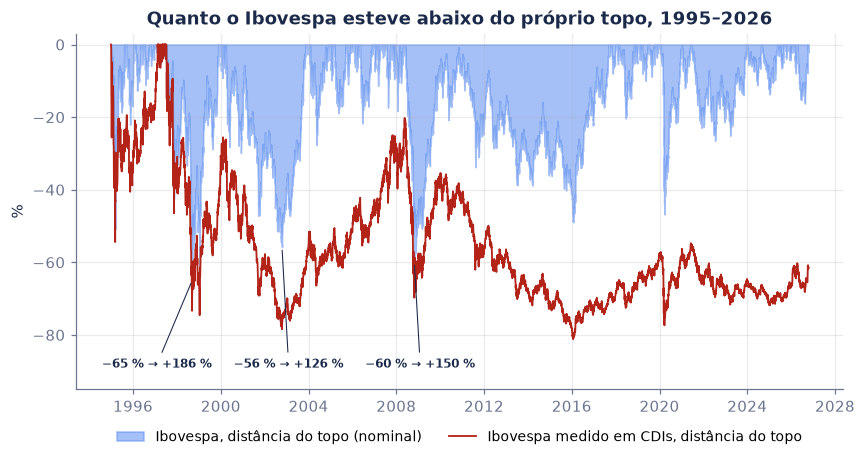

In [22]:
topo = ibov.cummax(); dd = ibov / topo - 1
eps, dentro = [], False
for d, v in dd.items():
    if v < 0 and not dentro:
        dentro, ini = True, ant
    elif v == 0 and dentro:
        seg = dd.loc[ini:d]; eps.append((ini, seg.idxmin(), seg.min(), d)); dentro = False
    ant = d
if dentro:
    seg = dd.loc[ini:]; eps.append((ini, seg.idxmin(), seg.min(), None))
E = pd.DataFrame(eps, columns=["topo", "fundo", "queda", "volta"]).sort_values("queda").head(6)
mostra(pd.DataFrame({"topo": E.topo.dt.strftime("%d/%m/%Y"), "fundo": E.fundo.dt.strftime("%d/%m/%Y"), "queda": [pc(v) for v in E.queda],
                     "alta para voltar, eq. (3)": [pcs(1 / (1 + v) - 1) for v in E.queda],
                     "voltou ao topo em": ["ainda não" if pd.isna(v) else v.strftime("%d/%m/%Y") for v in E.volta],
                     "anos do topo à volta": ["—" if pd.isna(v) else br((v - t).days / 365.25, 1) for t, v in zip(E.topo, E.volta)]}),
       "As seis maiores quedas do Ibovespa desde 1995 (nominal)")
cdi_idx = idx_cdi / idx_cdi.iloc[0]                          # CDI acumulado desde 29/12/1994, nas datas de pregão
rel = ibov / cdi_idx                                        # Ibovespa medido em "CDIs"
dd_rel = rel / rel.cummax() - 1
lr = math.log(ibov.iloc[-1] / ibov.iloc[0]) - math.log(cdi_idx.iloc[-1] / cdi_idx.iloc[0])   # (5): o log da razão é a diferença dos logs
print(f"contra o CDI: o topo do Ibovespa medido em CDIs foi em {rel.idxmax():%d/%m/%Y}; a maior queda, {pc(dd_rel.min())} em {dd_rel.idxmin():%d/%m/%Y}; em 16/10/2026, ainda {pc(dd_rel.iloc[-1])}")
print(f"de 29/12/1994 a 16/10/2026: retorno log do Ibovespa {br(math.log(ibov.iloc[-1] / ibov.iloc[0]), 3)} − retorno log do CDI {br(math.log(cdi_idx.iloc[-1] / cdi_idx.iloc[0]), 3)} = {br(lr, 3)}"
      f" → o Ibovespa terminou valendo {br(math.exp(lr), 3)} vez o que o CDI entregou ({pcs(math.expm1(lr))} contra o CDI)")
assert round(100 * E.queda.iloc[0], 1) == -65.0

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.fill_between(dd.index, 100 * dd, 0, color=LIGHT, alpha=0.55, label="Ibovespa, distância do topo (nominal)")
ax.plot(dd_rel.index, 100 * dd_rel, color=RED, lw=1.2, label="Ibovespa medido em CDIs, distância do topo")
for (_, e), x_txt in zip(E.head(3).sort_values("fundo").iterrows(), ("1994-08-01", "2000-08-01", "2006-08-01")):
    ax.annotate(f"{pc(e.queda, 0)} → +{br(100 * (1 / (1 + e.queda) - 1), 0)} %", (e.fundo, 100 * e.queda), (pd.Timestamp(x_txt), -89), fontsize=8, color=NAVY, weight="bold",
                arrowprops=dict(arrowstyle="-", color=NAVY, lw=0.7))
ax.set(title="Quanto o Ibovespa esteve abaixo do próprio topo, 1995–2026", ylabel="%", ylim=(-95, 3))
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=9); plt.show()

**Leitura.** A queda de 2008 (−60 %) pedia +150 % e levou mais de nove anos para ser recuperada em reais correntes. A de 1997–98 (−65 %) pedia +186 %. E medido contra o CDI, que é o custo de oportunidade do investidor brasileiro, o Ibovespa nunca voltou ao topo de julho de 1997. Com logs, essa conta é uma subtração: o retorno log do Ibovespa menos o do CDI.

## 12. O que este modelo não vê

1. **Caudas grossas.** O modelo clássico (seção 6) supõe retornos log normais. O Ibovespa diário tem curtose muito acima de 3 e dias de −15,8 % e +33,4 %, que uma normal com a mesma volatilidade praticamente proíbe. A eq. (7) descreve o centro da distribuição, não as crises.
2. **Inflação, custos e impostos.** Tudo aqui está em reais correntes. O Ibovespa já reinveste proventos, mas não desconta corretagem, imposto de renda nem inflação, e as ações do Yahoo são ajustadas por proventos sem imposto.
3. **A média do passado não é o retorno do futuro.** Na seção 9, o erro-padrão da média anual do Ibovespa passa de 5 pontos. A diferença entre as médias simples e log é precisa; o nível de cada uma, não. Para projetar riqueza em prazos longos, nem a média aritmética nem a geométrica são não viesadas (Jacquier, Kane e Marcus, 2003).
4. **Posições que podem zerar.** O log pressupõe valor positivo. Alavancagem, venda a descoberto, long-short sem capital e opções podem levar a −100 % ou além, e aí o retorno log não existe (seção 10).
5. **Datas e frequência.** A diferença entre simples e log depende da frequência (diária, mensal, anual): a eq. (9) usa a variância **daquela** frequência. Comparar médias de frequências diferentes sem converter é outro erro comum.

In [23]:
c4 = ((ri - ri.mean()) ** 4).mean() / ri.var(ddof=0) ** 2
print(f"curtose dos retornos log diários do Ibovespa, 1995–2026: {br(c4, 1)} (normal = 3)")
z = (ri.min() - ri.mean()) / ri.std()
chance = 0.5 * math.erfc(abs(z) / math.sqrt(2))
print(f"o pior dia ({ri.idxmin():%d/%m/%Y}, {pcs(Ri.min())}) está a {br(abs(z), 1)} desvios-padrão da média; numa normal, a chance de um dia assim é de cerca de 1 em 10^{int(math.log10(1 / chance))}")

curtose dos retornos log diários do Ibovespa, 1995–2026: 18,4 (normal = 3)
o pior dia (10/09/1998, −15,8 %) está a 8,8 desvios-padrão da média; numa normal, a chance de um dia assim é de cerca de 1 em 10^18


### Para praticar (respostas na célula seguinte)

1. Uma ação cai 20 % num dia e sobe 20 % no seguinte. Onde ela termina? Quanto precisava ter subido?
2. Os retornos log de uma semana foram +0,02, −0,03, +0,01, +0,04 e −0,01. Qual o retorno da semana em %?
3. Uma carteira tem 60 % na ação A, que subiu 30 % no ano, e 40 % na B, que caiu 10 %. Qual o retorno da carteira? E quanto daria a média ponderada dos retornos log, convertida?
4. Um fundo divulga "média de 2 % ao mês", com desvio-padrão mensal de 10 %. Quanto ele rende por mês, de verdade, aproximadamente? E em 12 meses?
5. O CDI está em 14,15 % ao ano (base 252). Qual a taxa por dia útil? Se você somar 252 dessas taxas, quanto dá?

In [24]:
print("1)", f"0,8 × 1,2 − 1 = {pcs(0.8 * 1.2 - 1, 1)}; para voltar, eq. (3): 1/0,8 − 1 = {pcs(1 / 0.8 - 1, 1)}")
w_ = np.array([0.02, -0.03, 0.01, 0.04, -0.01])
print("2)", f"soma dos logs = {br(w_.sum(), 2)}; eq. (5): e^{br(w_.sum(), 2)} − 1 = {pcs(np.expm1(w_.sum()), 2)}")
print("3)", f"eq. (8): 0,6 × 30 % + 0,4 × (−10 %) = {pcs(0.6 * 0.3 - 0.4 * 0.1, 1)}; média ponderada dos logs convertida: {pcs(np.expm1(0.6 * math.log(1.3) + 0.4 * math.log(0.9)), 2)} (menor, por Jensen)")
print("4)", f"eq. (9): 2 % − 0,10²/2 = {pc(0.02 - 0.1 ** 2 / 2, 1)} ao mês; em 12 meses ≈ {pc((1 + 0.02 - 0.1 ** 2 / 2) ** 12 - 1, 1)} (e não {pc(1.02 ** 12 - 1, 1)})")
d_ = 1.1415 ** (1 / 252) - 1
print("5)", f"1,1415^(1/252) − 1 = {br(100 * d_, 5)} % ao dia; 252 × isso = {pc(252 * d_, 2)} ≈ ln(1,1415) = {pc(math.log(1.1415), 2)}, a taxa contínua")

1) 0,8 × 1,2 − 1 = −4,0 %; para voltar, eq. (3): 1/0,8 − 1 = +25,0 %
2) soma dos logs = 0,03; eq. (5): e^0,03 − 1 = +3,05 %
3) eq. (8): 0,6 × 30 % + 0,4 × (−10 %) = +14,0 %; média ponderada dos logs convertida: +12,22 % (menor, por Jensen)
4) eq. (9): 2 % − 0,10²/2 = 1,5 % ao mês; em 12 meses ≈ 19,6 % (e não 26,8 %)
5) 1,1415^(1/252) − 1 = 0,05253 % ao dia; 252 × isso = 13,24 % ≈ ln(1,1415) = 13,23 %, a taxa contínua


---

### Resumo de fórmulas

| | Fórmula | Neste notebook |
|---|---|---|
| (1) Retorno simples | $R_t = P_t/P_{t-1} - 1$ | −50 % e +100 % |
| (2) Composição | $1 + R_{0\to T} = \prod_t (1 + R_t)$ | 0,5 × 2 = 1: de volta aos \$100 |
| (3) A alta que desfaz | $R^\ast = -R/(1+R)$ | −50 % pede +100 %; −90 % pede +900 % |
| (4) Retorno log | $r_t = \ln(P_t/P_{t-1}) = \ln(1+R_t)$ | ∓0,6931 |
| (5) Soma no tempo | $r_{0\to T} = \sum_t r_t$, $R_{0\to T} = e^{\sum r_t} - 1$ | −25,0 % exato, e todos os anos do Ibovespa |
| (6) Taylor | $\sum r_t \approx \sum R_t - \tfrac12\sum R_t^2$ | a lacuna de 4,83 pontos no ano simulado |
| (7) Preço lognormal | mediana $P_0 e^{mT}$, média $P_0 e^{mT + s^2T/2}$ | média \$100, mediana ≈ \$95 |
| (8) Carteira | $R_p = \sum_i w_i R_i$ | simples soma entre ativos |
| (9) Hudson & Gregoriou | $\bar r \approx \bar R - s^2/2$ | 38 ações da B3: inclinação ≈ 1 |

### Referências

- Campbell, J. Y.; Lo, A. W.; MacKinlay, A. C. (1997). *The Econometrics of Financial Markets*. Princeton University Press, cap. 1.
- Hudson, R. S.; Gregoriou, A. (2015). Calculating and comparing security returns is harder than you think: a comparison between logarithmic and simple returns. *International Review of Financial Analysis*, 38, 151–162.
- Jacquier, E.; Kane, A.; Marcus, A. J. (2003). Geometric or arithmetic mean: a reconsideration. *Financial Analysts Journal*, 59(6), 46–53.
- Cheng, M.; Madhavan, A. (2009). The dynamics of leveraged and inverse exchange-traded funds. *Journal of Investment Management*, 7(4), 43–62.
- Osborne, M. F. M. (1959). Brownian motion in the stock market. *Operations Research*, 7(2), 145–173.
- Künsch, H. R. (1989). The jackknife and the bootstrap for general stationary observations. *The Annals of Statistics*, 17(3), 1217–1241.
- Dados: B3 (Ibovespa, via Yahoo Finance `^BVSP`); Banco Central do Brasil, SGS, série 12 (CDI); Yahoo Finance (ações ajustadas).

*Gabriel Pires · [gabrielppires.com](https://gabrielppires.com) · [@gabrielp.piress](https://instagram.com/gabrielp.piress) · O vídeo é inspirado em* Quant Finance from Scratch*, de [@quantfinancetogo](https://instagram.com/quantfinancetogo). Números do vídeo nas seções 0–7 (preços simulados); dados reais nas seções 8–12. Só educação, não é recomendação de investimento.*